# Is α_rs degenerate with an isotropic dilation? BAO template, DESI DR1 FS+BAO
Model: $P_{\rm lin}(k)=a(k)\,T_{\rm nw}(k)\,[1+(1+A)\,e^{-k^2\Delta\Sigma^2/2}\,O(\alpha_{r_s}k)]$, AP from $\alpha_\parallel(z)=D_H/D_H^{\rm fid}$, $\alpha_\perp(z)=D_M/D_M^{\rm fid}$ (Mpc/h, no $r_d$), post-recon BAO points $=\alpha/\alpha_{r_s}$.

Gauge $T_\lambda$: $\alpha_{r_s}\to\lambda\alpha_{r_s}$, every $\alpha\to\lambda\alpha$, $a(k)\to\lambda^3a(\lambda k)\,T_{\rm nw}(\lambda k)/T_{\rm nw}(k)$, $\Delta\Sigma^2\to\lambda^2\Delta\Sigma^2$, EFT $c\to\lambda^n c$ ($n$ = k-dimension of the term). In the continuum it changes no observable (the loops are dilation covariant, the BAO points see $\alpha/\alpha_{r_s}$).

$\Delta\chi^2=-2\,\Delta\ln L$ of the analysis likelihood (12 EFT parameters fixed or re-fitted, 42 profiled with their Gaussian priors), no MI prior, from the MI best fit. Mock: noiseless, true ΛCDM at the data's best fit. `checks.py degeneracy`, CPU, float64.

In [1]:
import sys; sys.path.insert(0, '../mi')
import plots as P

## 1. α_rs alone vs an isotropic BAO dilation
Moves, $\lambda=e^t$. A: $\alpha_{r_s}\to\lambda\alpha_{r_s}$. B: every $\alpha\to\alpha/\lambda$ (same BAO $\alpha/\alpha_{r_s}$ as A, broadband AP-dilated too). Bc: B with the broadband dilated back ($=T_{1/\lambda}$ applied to A).
Expected if $T$ is a symmetry: BAO-alone identical for A, B, Bc; $\chi^2$(Bc) = $\chi^2$(A); B differs at fixed broadband; A and B agree once ln a, A, ΔΣ², b1, c2 are re-fitted.

noiseless mock: Delta chi2 from the MI best fit (chi2 = 1.017)
   lam         A         B  Bc exact  Bc nodes   T exact   T nodes |   BAO: A        B       Bc        T
 0.950   106.199   177.048   106.792   106.517    -0.150    -0.145 |   94.994   94.994   94.994    0.000
 0.960    65.986   110.279    66.494    66.250    -0.120    -0.119 |   59.492   59.492   59.492    0.000
 0.970    36.169    60.447    36.479    36.335    -0.095    -0.095 |   32.737   32.737   32.737    0.000
 0.980    15.709    26.204    15.850    15.791    -0.060    -0.060 |   14.219   14.219   14.219    0.000
 0.990     3.849     6.393     3.899     3.881    -0.032    -0.032 |    3.457    3.457    3.457    0.000
 0.995     0.956     1.585     0.977     0.969    -0.014    -0.014 |    0.843    0.843    0.843    0.000
 1.000     0.000     0.000     0.000     0.000     0.000     0.000 |    0.000    0.000    0.000    0.000
 1.005     0.942     1.522     0.923     0.923     0.026     0.020 |    0.877    0.877    0.877  

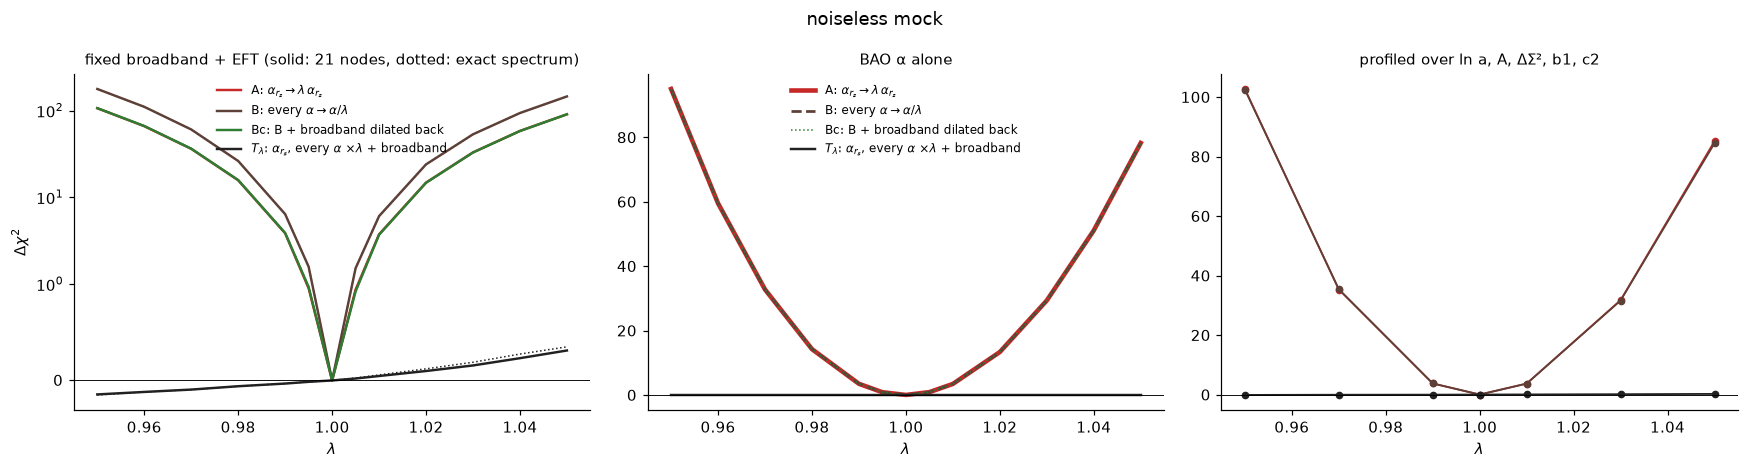

In [2]:
P.deg_moves('mock');

DESI DR1 FS+BAO: Delta chi2 from the MI best fit (chi2 = 275.924)
   lam         A         B  Bc exact  Bc nodes   T exact   T nodes |   BAO: A        B       Bc        T
 0.950   128.287   214.956   173.034   153.277    51.358    47.840 |   97.375   97.375   97.375   -0.000
 0.960    81.509   139.489   114.681   100.792    36.645    33.544 |   61.383   61.383   61.383   -0.000
 0.970    44.987    80.434    64.984    58.657    22.717    20.215 |   34.145   34.145   34.145   -0.000
 0.980    18.875    36.623    28.489    26.635    11.003     9.328 |   15.151   15.151   15.151   -0.000
 0.990     4.472     9.257     6.639     6.589     2.966     2.429 |    3.920    3.920    3.920   -0.000
 0.995     1.145     2.301     1.434     1.597     0.953     0.731 |    1.073    1.073    1.073   -0.000
 1.000     0.000     0.000     0.000     0.000     0.000     0.000 |    0.000    0.000    0.000    0.000
 1.005     1.054     2.366     1.732     1.598     0.690     0.593 |    0.648    0.648    0.64

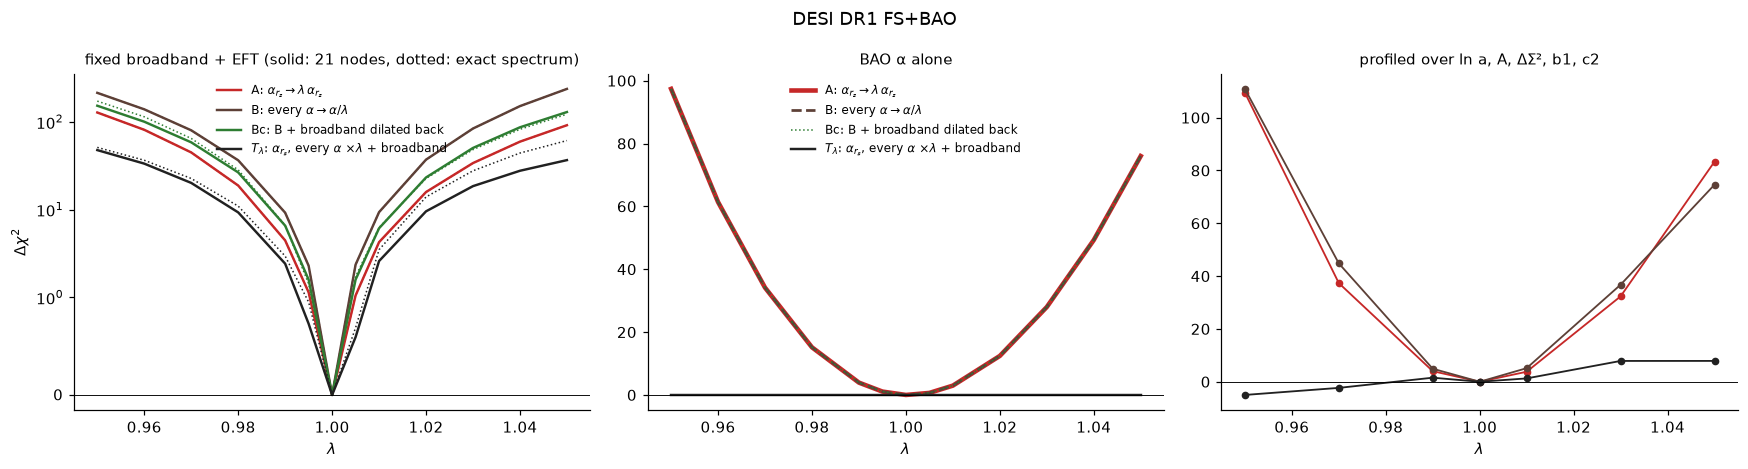

In [3]:
P.deg_moves('data');

## 2. The flat direction $T_\lambda$, and what breaks it
$\Delta\chi^2$ along $T_\lambda$ with the exact transformed spectrum, one ingredient added at a time. Exact one-loop without IR resummation is pure SPT: 0 up to numerics. Marginalizing the 42 EFT parameters instead of profiling them adds the Jacobian $\lambda^{\Sigma n}$ through log det F₂: $-2\Sigma n\ln\lambda$.

noiseless mock: Delta chi2 along T_lam (exact transformed spectrum unless 'nodes')
   lam  exact_noresum_      exact_wide            wide        analysis           nodes  marg_wide  -2 Sn lnlam
 0.950          0.1552          0.0395          0.0489         -0.1503         -0.1449     11.558       11.695
 0.980          0.0922          0.0233          0.0283         -0.0598         -0.0599      4.682        4.606
 0.990          0.0390          0.0224          0.0137         -0.0319         -0.0322      2.331        2.291
 1.000          0.0000          0.0000          0.0000          0.0000          0.0000      0.000       -0.000
 1.010          0.0376         -0.0043         -0.0055          0.0577          0.0462     -2.297       -2.269
 1.020          0.0638         -0.0001         -0.0051          0.1205          0.0980     -4.506       -4.515
 1.050          0.1442          0.0208          0.0227          0.3485          0.3108    -10.950      -11.124
chi2 at lam = 1 per variant: 

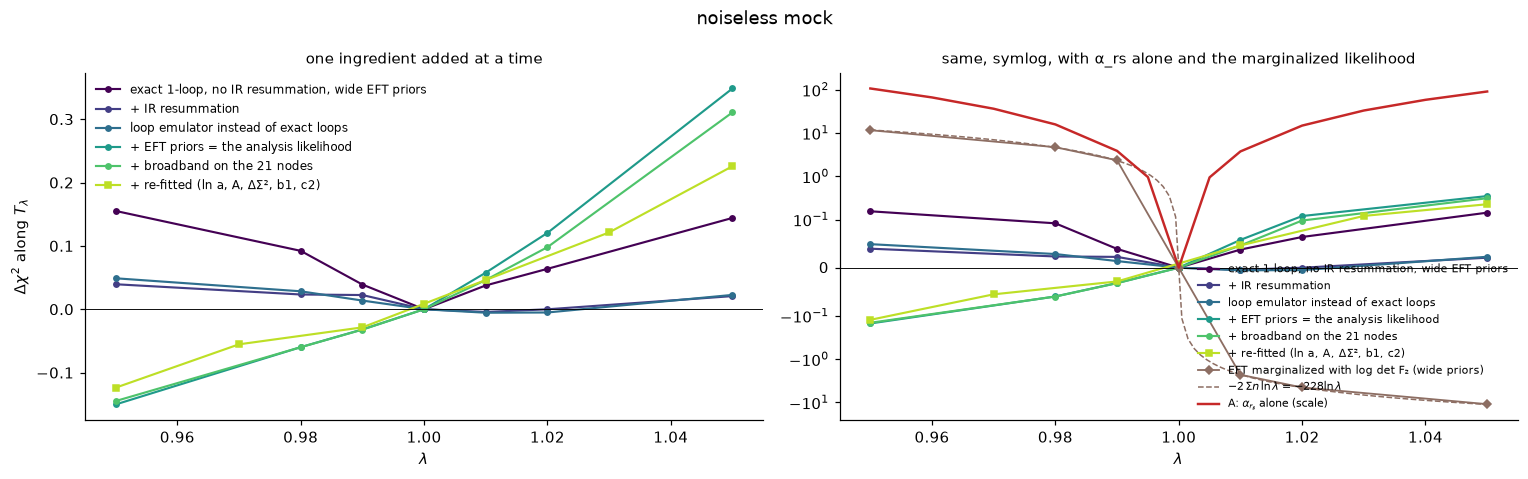

In [4]:
P.deg_ladder('mock');

DESI DR1 FS+BAO: Delta chi2 along T_lam (exact transformed spectrum unless 'nodes')
   lam  exact_noresum_      exact_wide            wide        analysis           nodes  marg_wide  -2 Sn lnlam
 0.950         -0.2262         -0.0002         50.3449         51.3576         47.8401     53.326       11.695
 0.980          0.0547          0.0798         11.5226         11.0028          9.3281     12.898        4.606
 0.990          0.2851          0.1072          3.2798          2.9664          2.4290      4.084        2.291
 1.000          0.0000          0.0000          0.0000          0.0000          0.0000      0.000       -0.000
 1.010         -0.1303         -0.2035          2.2615          3.5060          2.6007      1.686       -2.269
 1.020         -0.0147         -0.0795         10.8165         13.9882          9.5901      9.350       -4.515
 1.050         -0.0920         -0.2984         53.6864         61.4420         36.7732     46.534      -11.124
chi2 at lam = 1 per variant:

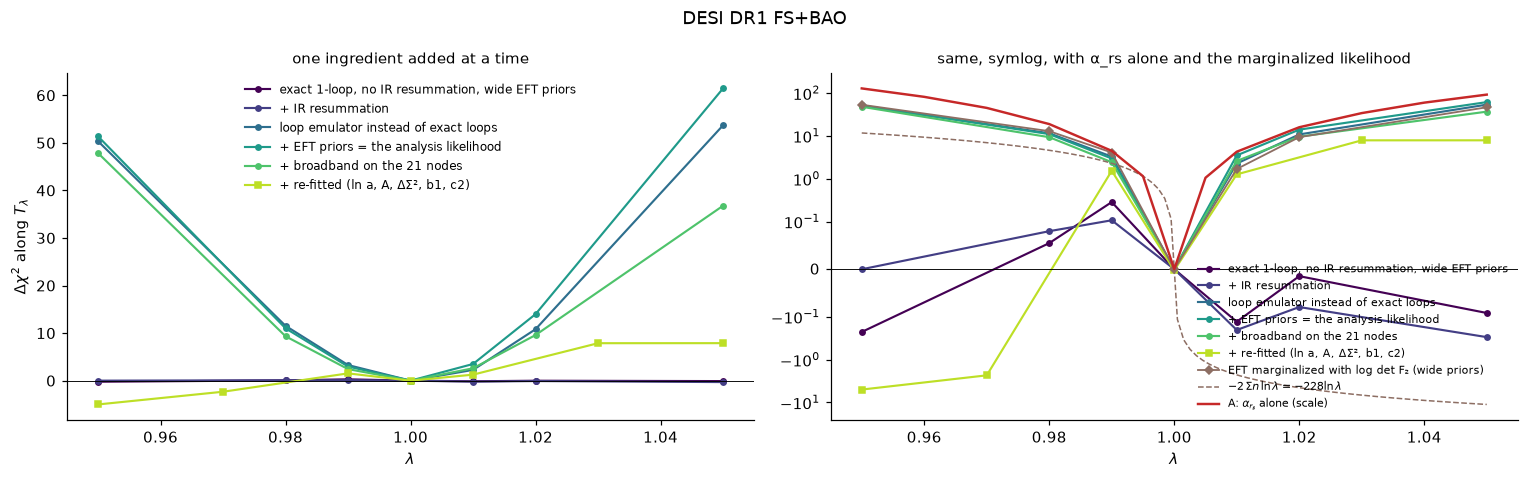

In [5]:
P.deg_ladder('data');

Each of the 42 EFT templates in observed space at $T_{1.02}$ against the best fit: $T'=\lambda^{-n}T$ measured bin by bin.

In [6]:
P.deg_eft_powers('mock')

noiseless mock: EFT templates at T_1.02 vs the best fit, T' = lam^-n T; median n over the k-bins (5-95% spread)
sky                b3            cct            cr1            cr2            ce0            ce1            ce2
pred.               0              2              2              2              3              5              5
BGS     +0.951 (9e-01)  +2.010 (2e-01)  +2.037 (2e-01)  +2.039 (2e-01)  +3.000 (6e-14)  +5.000 (4e-03)  +5.000 (1e-03)
LRG1    +0.908 (9e-01)  +2.018 (2e-01)  +2.024 (1e-01)  +2.024 (1e-01)  +3.000 (5e-14)  +5.000 (4e-03)  +5.000 (2e-03)
LRG2    +0.904 (8e-01)  +2.016 (2e-01)  +2.026 (1e-01)  +2.027 (1e-01)  +3.000 (6e-14)  +5.000 (4e-03)  +5.000 (1e-03)
LRG3    +0.888 (8e-01)  +2.018 (2e-01)  +2.022 (1e-01)  +2.020 (1e-01)  +3.000 (5e-14)  +5.000 (3e-03)  +5.000 (1e-03)
ELG2    +0.875 (8e-01)  +2.013 (1e-01)  +2.019 (8e-02)  +2.018 (8e-02)  +3.000 (8e-14)  +5.000 (1e-03)  +5.000 (7e-04)
QSO     +0.878 (8e-01)  +2.011 (1e-01)  +2.021 (8e-02)  +2.020 (8e-02

## 3. Fisher
$F=X^\top X$: Gauss–Newton Fisher of the analysis likelihood at the best fit over the 59 MI parameters (data: P0, P2 and the BAO α), the 42 profiled EFT parameters eliminated with their priors (QR projection, $F$ never formed), no MI prior.
Curvature along a direction $d$ (per unit $\ln\lambda$): $\kappa=d^\top Fd$, so $\Delta\chi^2\simeq\kappa\,(\ln\lambda)^2$. Gauge vector $v=dT_\lambda/d\ln\lambda$ (broadband part: the dilation projected on the 21 nodes).
Tests: $\kappa(v)\ll\kappa(A)$; A and Bc fully correlated ($\rho\to1$); where $v$ sits among the eigenvectors of the prior-whitened Fisher (eigenvalue = data/prior information); the data's own best compensation of an α_rs move (minimum χ² with $d\ln\alpha_{r_s}=1$; directions the data cannot see fixed by $10^{-3}\times$ the MI prior) against $v$.

noiseless mock, analysis likelihood (loop emulator): Gauss-Newton Fisher check, -2 ln L rebuilt from residuals 1.0173 vs likelihood 1.0173
curvature kappa per unit ln lam and sigma = kappa^-1/2:  A 3.799e+04 (0.00513), B 6.216e+04 (0.00401), Bc 3.782e+04 (0.00514), T 161.4 (0.0787), α_rs + the data's best
compensation 97.02 (0.102)
kappa(T) / kappa(A) = 4.25e-03;  correlation of A and Bc: rho = 0.99787291 (1 - rho = 2.13e-03)
cos(gauge, softest eigenvector) = 0.0036;  fraction of the gauge in directions the data inform less than the prior (eigenvalue < 1): 0.9988;  data/prior information along the gauge 0.288 vs along alpha_rs alone 95
A, dSigma^2 (barely constrained by the data, so its best compensation is arbitrary): gauge v +0.000, -0.832;  data best compensation +0.092, +187.525


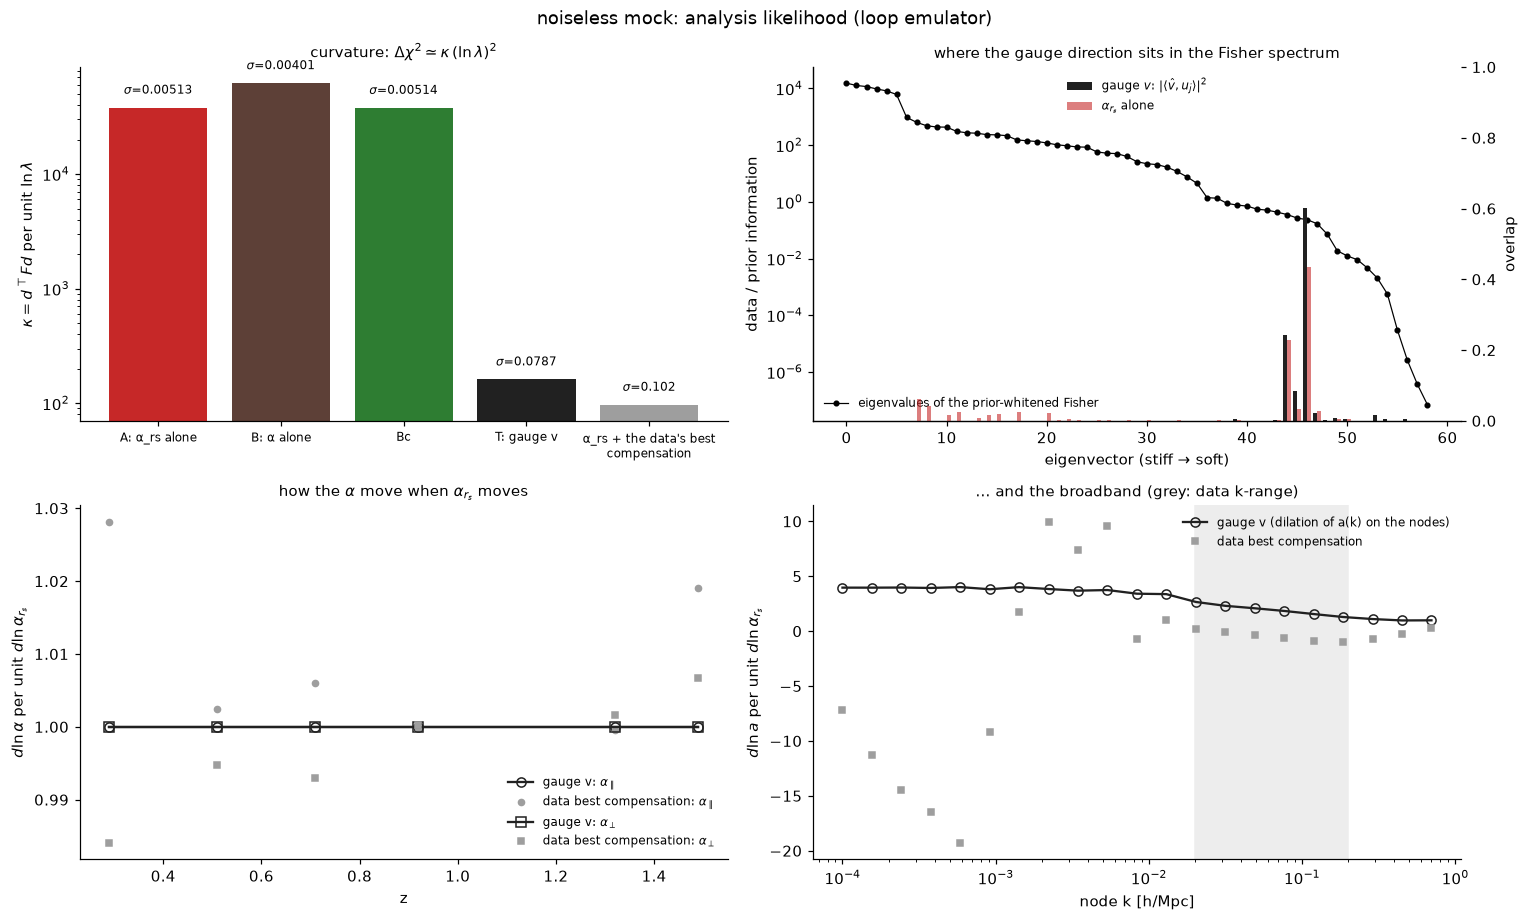

In [7]:
P.deg_fisher('mock');

DESI DR1 FS+BAO, analysis likelihood (loop emulator): Gauss-Newton Fisher check, -2 ln L rebuilt from residuals 275.9243 vs likelihood 275.9243
curvature kappa per unit ln lam and sigma = kappa^-1/2:  A 4.167e+04 (0.0049), B 8.832e+04 (0.00336), Bc 5.62e+04 (0.00422), T 1.723e+04 (0.00762), α_rs + the data's best
compensation 5733 (0.0132)
kappa(T) / kappa(A) = 4.14e-01;  correlation of A and Bc: rho = 0.83316299 (1 - rho = 1.67e-01)
cos(gauge, softest eigenvector) = 0.0021;  fraction of the gauge in directions the data inform less than the prior (eigenvalue < 1): 0.1007;  data/prior information along the gauge 27.5 vs along alpha_rs alone 104
A, dSigma^2 (barely constrained by the data, so its best compensation is arbitrary): gauge v +0.000, -56.592;  data best compensation -5.452, -29.968


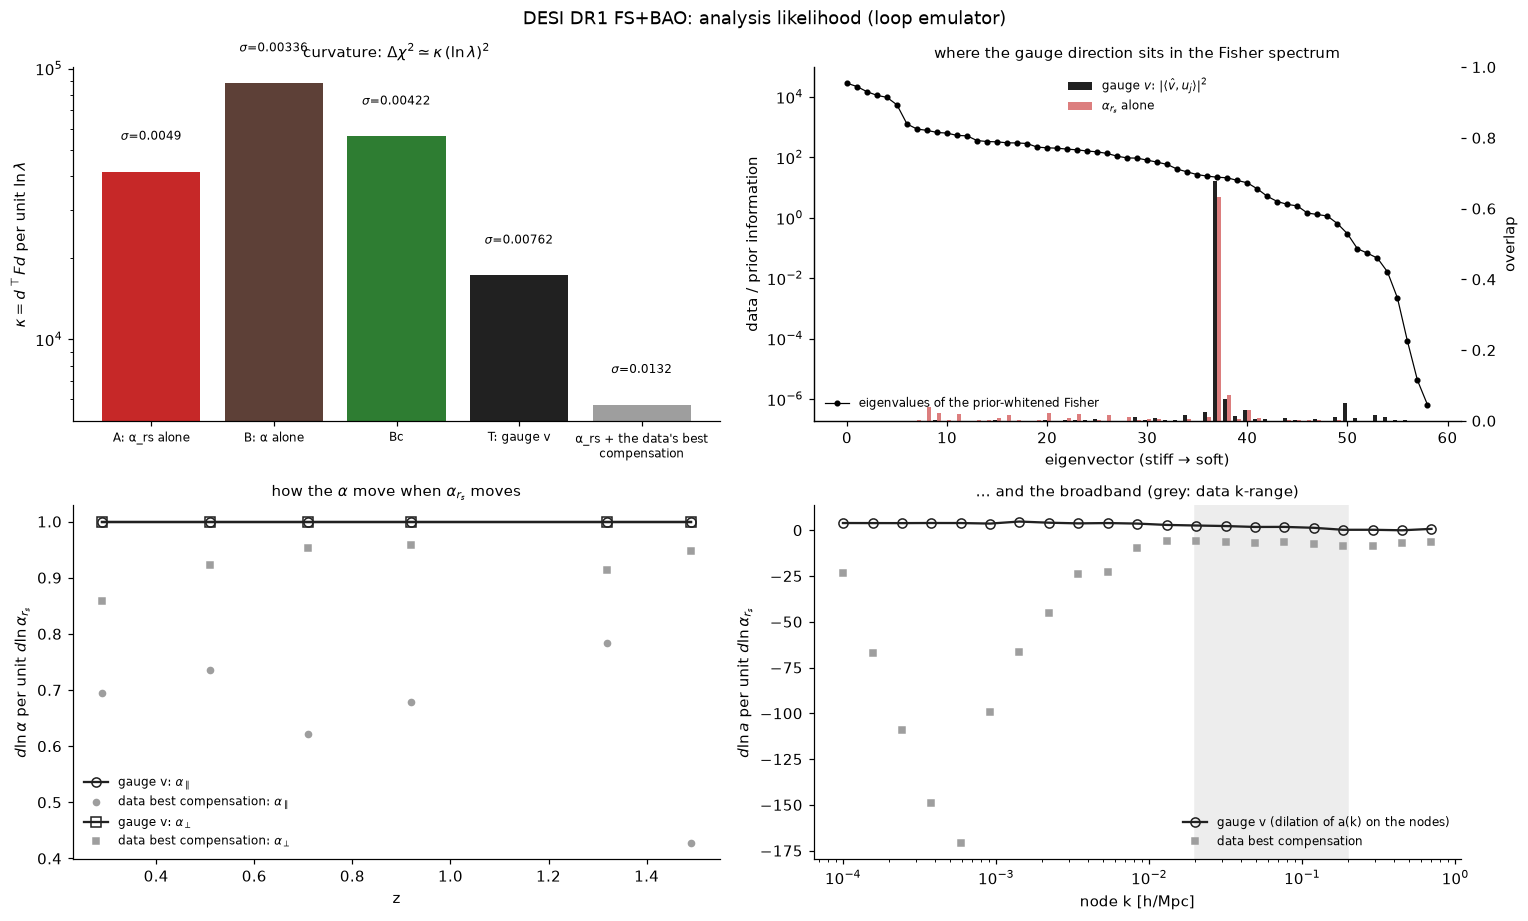

In [8]:
P.deg_fisher('data');

The same with exact one-loop (FFTLog) instead of the loop emulator, wide EFT priors.

noiseless mock, exact one-loop, wide EFT priors: Gauss-Newton Fisher check, -2 ln L rebuilt from residuals 0.3199 vs likelihood 0.3199
curvature kappa per unit ln lam and sigma = kappa^-1/2:  A 3.793e+04 (0.00513), B 4.975e+04 (0.00448), Bc 3.779e+04 (0.00514), T 105.4 (0.0974), α_rs + the data's best
compensation 82.08 (0.11)
kappa(T) / kappa(A) = 2.78e-03;  correlation of A and Bc: rho = 0.99860936 (1 - rho = 1.39e-03)
cos(gauge, softest eigenvector) = 0.0090;  fraction of the gauge in directions the data inform less than the prior (eigenvalue < 1): 0.9986;  data/prior information along the gauge 0.188 vs along alpha_rs alone 94.8
A, dSigma^2 (barely constrained by the data, so its best compensation is arbitrary): gauge v +0.000, -0.832;  data best compensation +0.264, -523.875


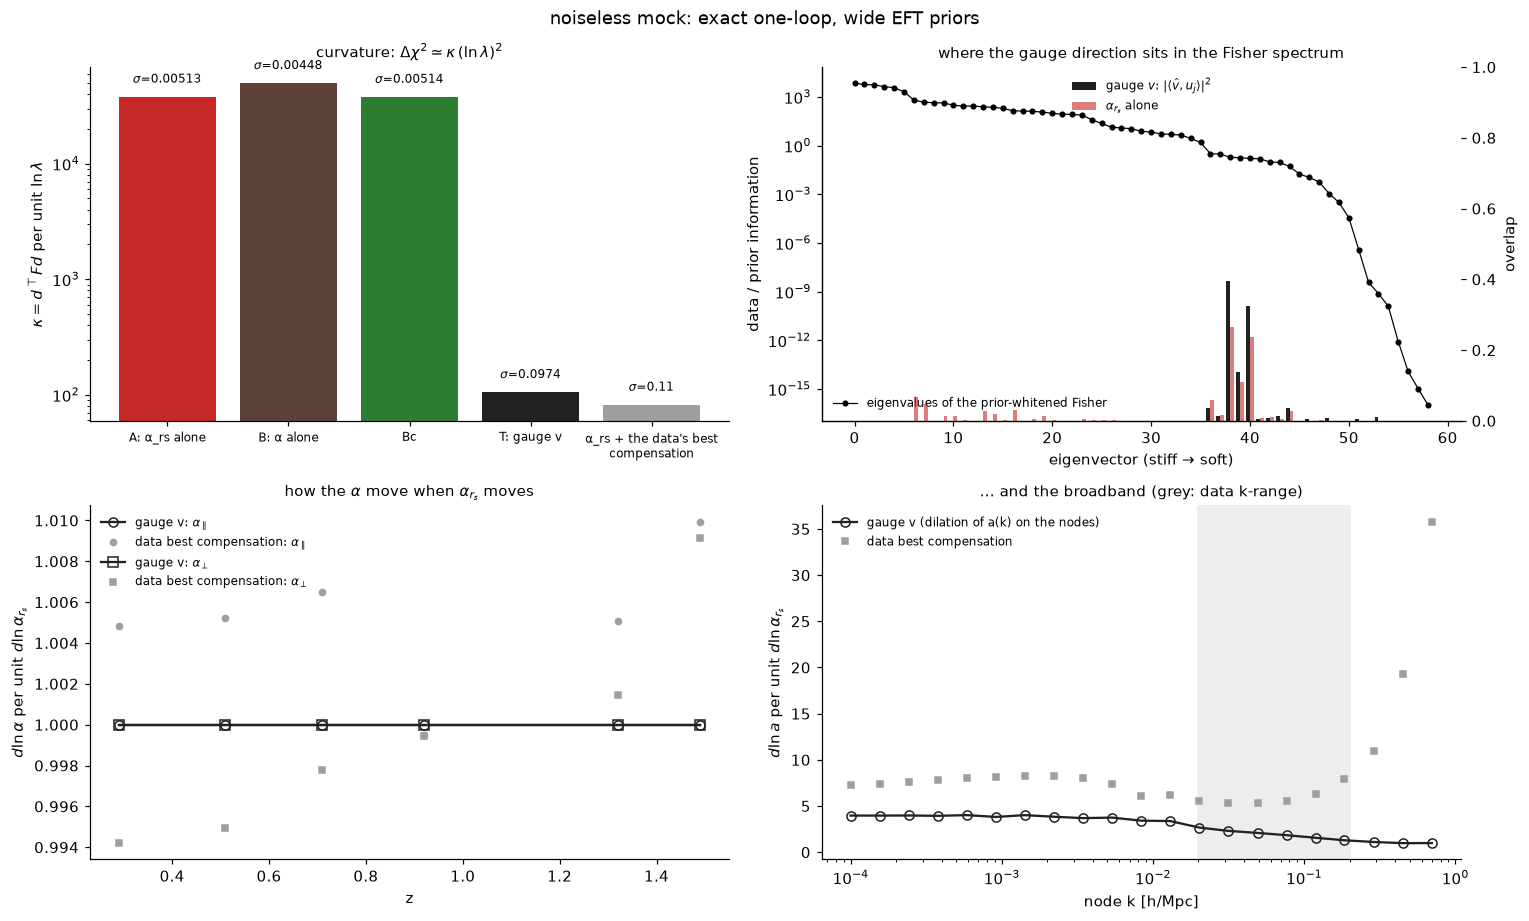

In [9]:
P.deg_fisher('mock', exact=True);

DESI DR1 FS+BAO, exact one-loop, wide EFT priors: Gauss-Newton Fisher check, -2 ln L rebuilt from residuals 306.0290 vs likelihood 306.0290
curvature kappa per unit ln lam and sigma = kappa^-1/2:  A 3.816e+04 (0.00512), B 5.095e+04 (0.00443), Bc 3.844e+04 (0.0051), T 455.2 (0.0469), α_rs + the data's best
compensation 125.9 (0.0891)
kappa(T) / kappa(A) = 1.19e-02;  correlation of A and Bc: rho = 0.99406327 (1 - rho = 5.94e-03)
cos(gauge, softest eigenvector) = 0.0010;  fraction of the gauge in directions the data inform less than the prior (eigenvalue < 1): 0.9783;  data/prior information along the gauge 0.727 vs along alpha_rs alone 95.4
A, dSigma^2 (barely constrained by the data, so its best compensation is arbitrary): gauge v +0.000, -56.592;  data best compensation -2.514, -715.130


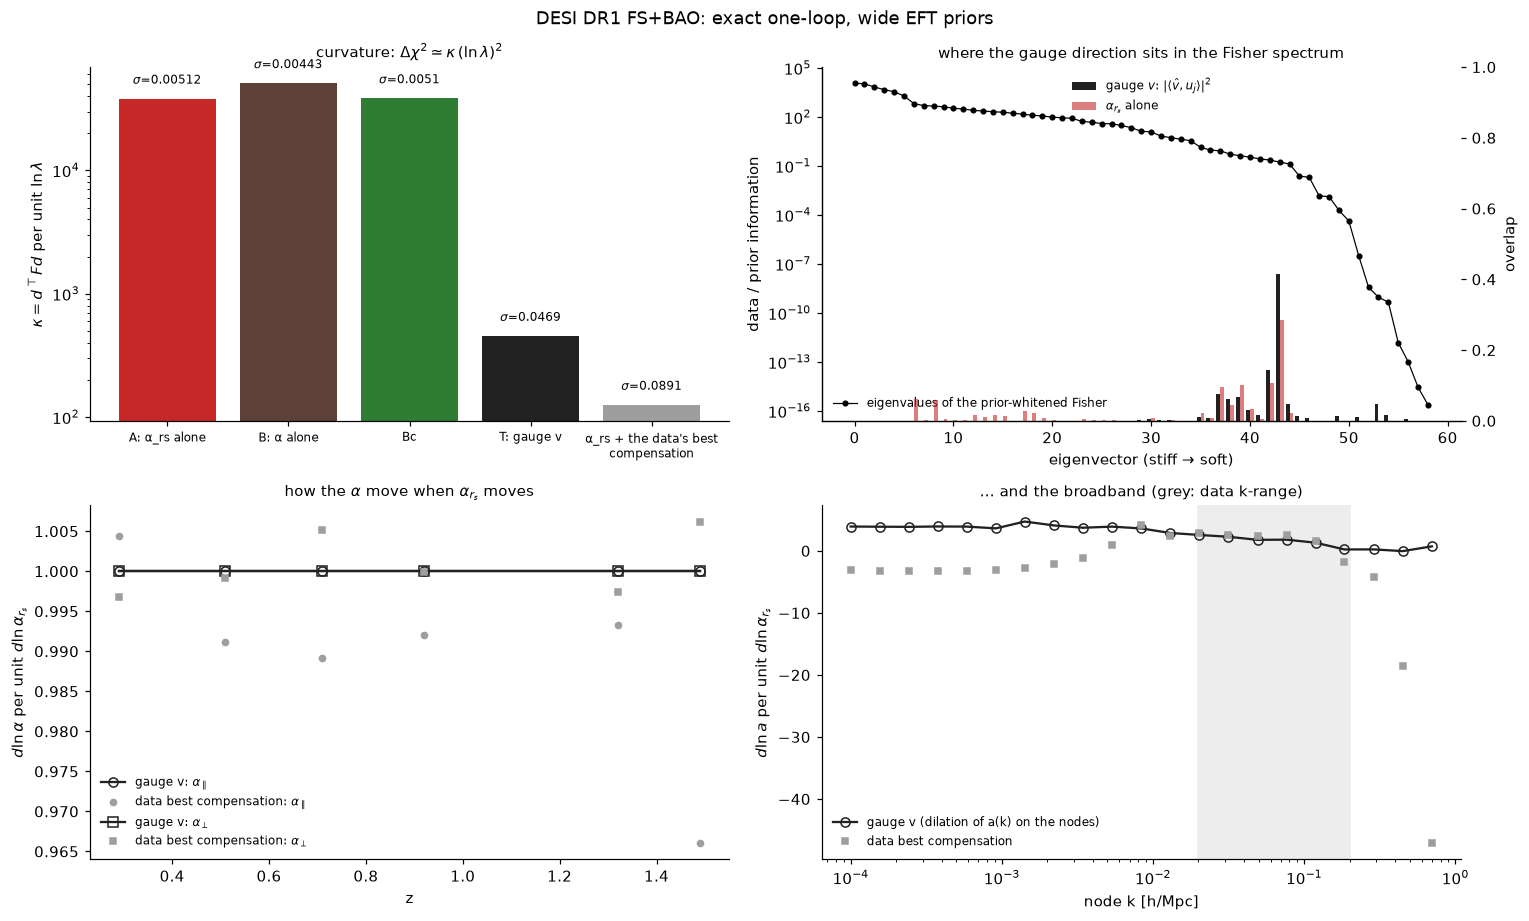

In [10]:
P.deg_fisher('data', exact=True);

## 4. Every draw mapped to α_rs = 1
$T_{1/\alpha_{r_s}}$ on 400 chain draws: $\alpha_{r_s}\to1$, $\alpha\to\alpha/\alpha_{r_s}$ (the BAO α), broadband dilated (the α_rs = 1 template with BAO-parametrized AP). On 80 of them also with wide EFT priors, and with exact loops.

noiseless mock, 80 of the draws, |Delta chi2| median / 95%: analysis 0.996 / 9.374, wide EFT priors 0.471 / 2.851, exact loops 0.061 / 0.272
noiseless mock: 400 draws, Delta chi2 after T_(1/alpha_rs): exact median +0.4715, 5-95% [-1.7147, +10.8875]; nodes median +0.4276, 5-95% [-2.5672, +7.5134]
DESI DR1 FS+BAO, 80 of the draws, |Delta chi2| median / 95%: analysis 2.842 / 18.174, wide EFT priors 3.530 / 17.620, exact loops 0.192 / 0.745
DESI DR1 FS+BAO: 400 draws, Delta chi2 after T_(1/alpha_rs): exact median +1.9761, 5-95% [-1.4651, +22.7479]; nodes median +2.1774, 5-95% [-1.4702, +24.9385]


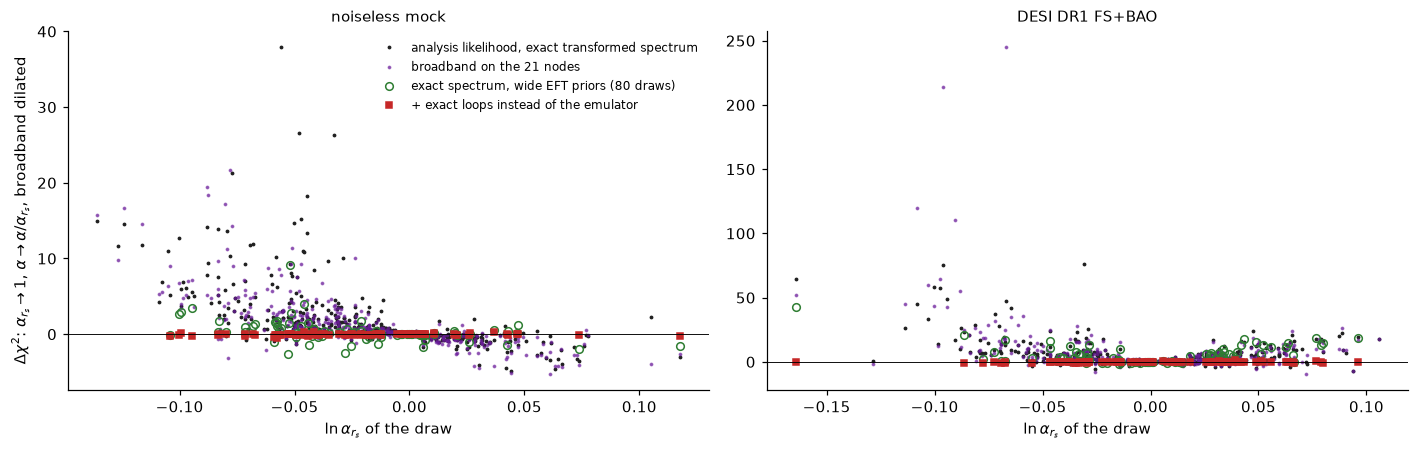

In [11]:
P.deg_map();

## 5. The posterior along the ridge
ln α_rs of the chains against the MI prior along $v$, $\sigma=(v^\top\Pi v)^{-1/2}$, and the likelihood alone along $v$, $\kappa(v)^{-1/2}$.

                 chain mean  chain sd  best fit    truth sd prior|v  sd lkl|v sd both|v sd lkl|v exact loops


noiseless mock      -0.0230    0.0420   +0.0002  +0.0261     0.0423    0.0787    0.0372               0.0974
DESI DR1 FS+BAO     -0.0012    0.0426   +0.0396     +nan     0.0400   0.00762    0.0075               0.0469


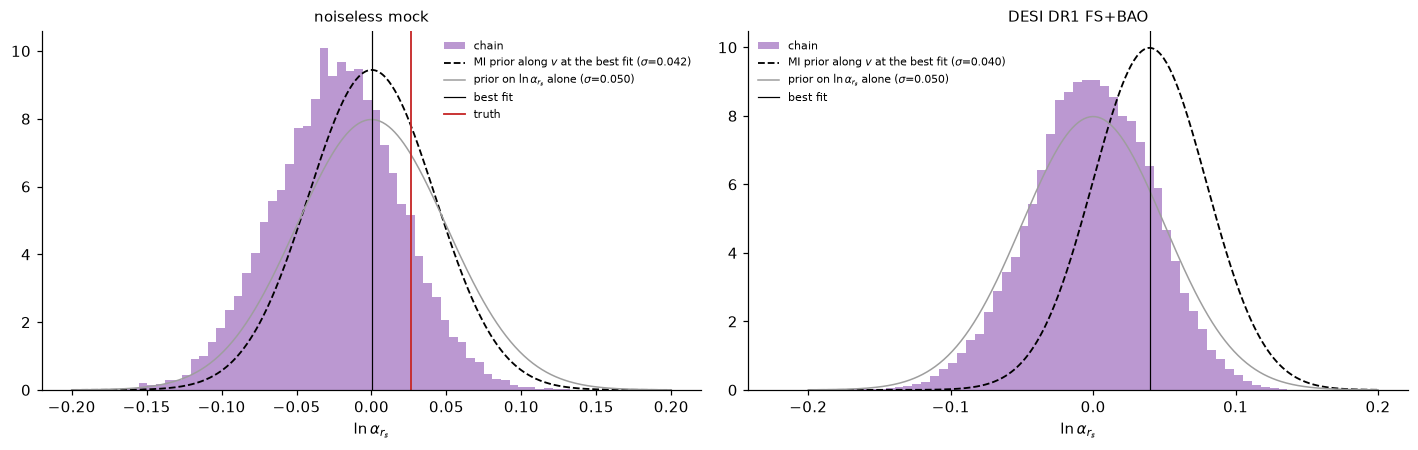

In [12]:
P.deg_ridge();